In [29]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pylab as plt

In [2]:
df = pd.read_csv('house-train.csv')

In [4]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
df2 = pd.read_csv('data_cleaning_auto.csv')

In [7]:
df2.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
df2 = df2[['Age','Fare','Survived']]

In [10]:
df2.head()

,Age,Fare,Survived
0,22.0,7.2500,0
1,38.0,71.2833,1
2,26.0,7.9250,1
3,35.0,53.1000,1
4,35.0,8.0500,0


In [12]:
df2.isnull().sum()

Age         177
Fare          0
Survived      0
dtype: int64

In [13]:
df2.isnull().mean() * 100

Age         19.86532
Fare         0.00000
Survived     0.00000
dtype: float64

In [16]:
X = df2.drop(columns=['Survived'])
y = df2['Survived']

In [17]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [18]:
X_train['Age_imputed'] = X_train['Age']
X_test['Age_imputed'] = X_test['Age']

In [36]:
# Impute X_train missing values
train_nulls = X_train['Age_imputed'].isnull()
if train_nulls.sum() > 0:
    train_samples = X_train['Age'].dropna().sample(n=train_nulls.sum(), random_state=42).values
    X_train.loc[train_nulls, 'Age_imputed'] = train_samples

# Impute X_test missing values using X_train's distribution
test_nulls = X_test['Age_imputed'].isnull()
if test_nulls.sum() > 0:
    test_samples = X_train['Age'].dropna().sample(n=test_nulls.sum(), random_state=42).values
    X_test.loc[test_nulls, 'Age_imputed'] = test_samples

In [37]:
X_train

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,18.0
493,71.0,49.5042,71.0
527,NaN,221.7792,21.0


<Axes: xlabel='Age', ylabel='Density'>

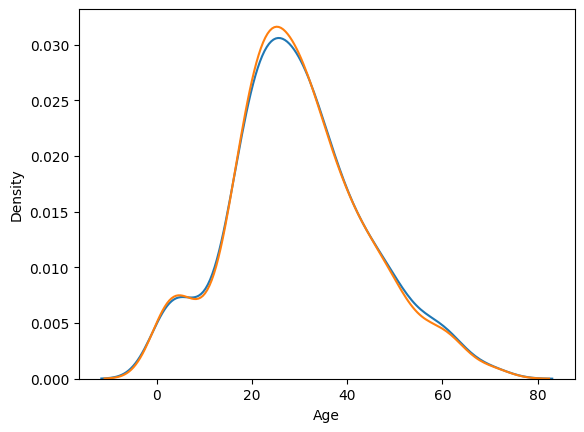

In [38]:
sns.kdeplot(X_train['Age'])
sns.kdeplot(X_train['Age_imputed'])

In [39]:
print(X_train['Age'].var())
print(X_train['Age_imputed'].var())

204.34951339046142
200.02896637747122


In [40]:
X_train.isnull().sum()

Age            148
Fare             0
Age_imputed      0
dtype: int64